# Frame rate limits of a live run

How fast can a live run capture before it suffers? It can suffer in three ways:

1. **Frames dropped**: the camera delivers faster than the app takes frames in (the 64-frame queue fills up).
2. **Analysis falling behind**: scoring a recording takes longer than the time to the next one (at least 1 min, `recording_timeout`), so recordings pile up in memory.
3. **Memory**: every frame of a recording is held until it is scored: a 2064 x 1544 frame is 3 MB grey.

`scripts/frame_rate_limits.py` runs the live path as it is (the camera's frame handler, the frame router, the burst, the Recorder writing BMPs, `LiveSession`, `MotionAnalysis` scoring every mite). Only the camera is a stand-in. It streams real frames of a recording folder at the frame rate asked, through the real `FrameHandler`. Each measurement is a fresh process. The camera's GigE transfer, the fan and LEDs, and the results sent to the page after each recording are not included.

The Discobox camera (Mako G-319B) goes up to **33 fps** (`classes/live/settings.py`). Frames per recording = fps x burst length.

**Run it on the Discobox laptop** for the numbers that count there: this notebook's outputs are from the Windows laptop (Core Ultra 7 155H, 22 threads), which is likely faster.

In [1]:
import os, platform, sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from frame_rate_limits import measure_apart

# A recording folder whose frames are streamed: the long run (59 mites) if it is here, else sample_data (30).
LONG_RUN = ROOT / "recordings" / "test_run_2026-09-08_Mathis_last_dsRNA"
DATA = LONG_RUN if LONG_RUN.is_dir() else ROOT / "sample_data"
# A checkout of the code before frames were held grey (commit 2fe59bd), to compare memory; None to skip.
# Make one with: git worktree add <path> 2fe59bd
OLD_CODE = Path(os.environ["TEMP"]) / "zzwt" if os.name == "nt" else None
OLD_CODE = OLD_CODE if OLD_CODE and (OLD_CODE / "pipeline.py").is_file() else None
CYCLE_S = 60  # the shortest time between two recordings (recording_timeout = 1 min)

print(platform.processor() or platform.machine(), os.cpu_count(), "logical processors")
print("frames from", DATA.name, "| old code:", OLD_CODE)

BLUE, ORANGE, AQUA, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8, "lines.linewidth": 2})

def sweep(configs, code=ROOT, **kwargs):
    rows = []
    for fps, frames in configs:
        row = measure_apart(DATA, fps, frames, code=code, **kwargs)
        print({key: row[key] for key in ("fps", "frame_count", "dropped", "capture_s", "score_s", "peak_mb")})
        rows.append(row)
    return pd.DataFrame(rows)

COLUMNS = ["fps", "frame_count", "mites", "dropped", "late", "expected_s", "capture_s", "score_s", "analysed_s", "peak_mb", "cpu"]

Intel64 Family 6 Model 170 Stepping 4, GenuineIntel 22 logical processors
frames from recordings | old code: C:\Users\mateo\AppData\Local\Temp\zzwt


## 1. Frame rate, 1 s bursts

Each recording is a 1 s burst (frames = fps), two recordings, the second started once the first is analysed, as the test run does.

In [2]:
by_fps = sweep([(fps, fps) for fps in (5, 10, 15, 20, 25, 30, 33)])
by_fps[COLUMNS]

{'fps': 5, 'frame_count': 5, 'dropped': 0, 'capture_s': 0.982, 'score_s': 0.329, 'peak_mb': 42.8}


{'fps': 10, 'frame_count': 10, 'dropped': 0, 'capture_s': 0.953, 'score_s': 0.438, 'peak_mb': 58.4}


{'fps': 15, 'frame_count': 15, 'dropped': 0, 'capture_s': 0.977, 'score_s': 0.547, 'peak_mb': 73.6}


{'fps': 20, 'frame_count': 20, 'dropped': 0, 'capture_s': 0.996, 'score_s': 0.568, 'peak_mb': 89.0}


{'fps': 25, 'frame_count': 25, 'dropped': 0, 'capture_s': 0.985, 'score_s': 0.746, 'peak_mb': 105.9}


{'fps': 30, 'frame_count': 30, 'dropped': 0, 'capture_s': 0.996, 'score_s': 0.771, 'peak_mb': 121.3}


{'fps': 33, 'frame_count': 33, 'dropped': 0, 'capture_s': 0.991, 'score_s': 0.831, 'peak_mb': 131.5}


,fps,frame_count,mites,dropped,late,expected_s,capture_s,score_s,analysed_s,peak_mb,cpu
0,5,5,60,0,0,1.0,0.982,0.329,0.381,42.8,0.36
1,10,10,60,0,0,1.0,0.953,0.438,0.506,58.4,0.60
2,15,15,60,0,0,1.0,0.977,0.547,0.627,73.6,0.68
3,20,20,60,0,0,1.0,0.996,0.568,0.622,89.0,0.84
4,25,25,60,0,0,1.0,0.985,0.746,0.842,105.9,0.96
5,30,30,60,0,0,1.0,0.996,0.771,0.831,121.3,1.09
6,33,33,60,0,0,1.0,0.991,0.831,0.895,131.5,1.18


## 2. Frames per recording, at 33 fps

The camera's top rate, with longer and longer bursts (up to 10 s). Scoring time and memory grow with the frames of a recording, not with the frame rate itself.

In [3]:
by_frames = sweep([(33, frames) for frames in (10, 33, 66, 100, 165, 330)])
by_frames[COLUMNS]

{'fps': 33, 'frame_count': 10, 'dropped': 0, 'capture_s': 0.298, 'score_s': 0.479, 'peak_mb': 59.4}


{'fps': 33, 'frame_count': 33, 'dropped': 0, 'capture_s': 0.979, 'score_s': 0.837, 'peak_mb': 130.2}


{'fps': 33, 'frame_count': 66, 'dropped': 0, 'capture_s': 1.987, 'score_s': 1.322, 'peak_mb': 238.3}


{'fps': 33, 'frame_count': 100, 'dropped': 0, 'capture_s': 3.019, 'score_s': 1.792, 'peak_mb': 355.0}


{'fps': 33, 'frame_count': 165, 'dropped': 0, 'capture_s': 4.995, 'score_s': 2.773, 'peak_mb': 579.9}


{'fps': 33, 'frame_count': 330, 'dropped': 0, 'capture_s': 9.996, 'score_s': 5.13, 'peak_mb': 1134.3}


,fps,frame_count,mites,dropped,late,expected_s,capture_s,score_s,analysed_s,peak_mb,cpu
0,33,10,60,0,0,0.303,0.298,0.479,0.533,59.4,1.09
1,33,33,60,0,1,1.000,0.979,0.837,0.913,130.2,1.17
2,33,66,60,0,1,2.000,1.987,1.322,1.390,238.3,1.25
3,33,100,60,0,0,3.030,3.019,1.792,1.854,355.0,1.24
4,33,165,60,0,0,5.000,4.995,2.773,2.845,579.9,1.29
5,33,330,60,0,0,10.000,9.996,5.130,5.232,1134.3,1.37


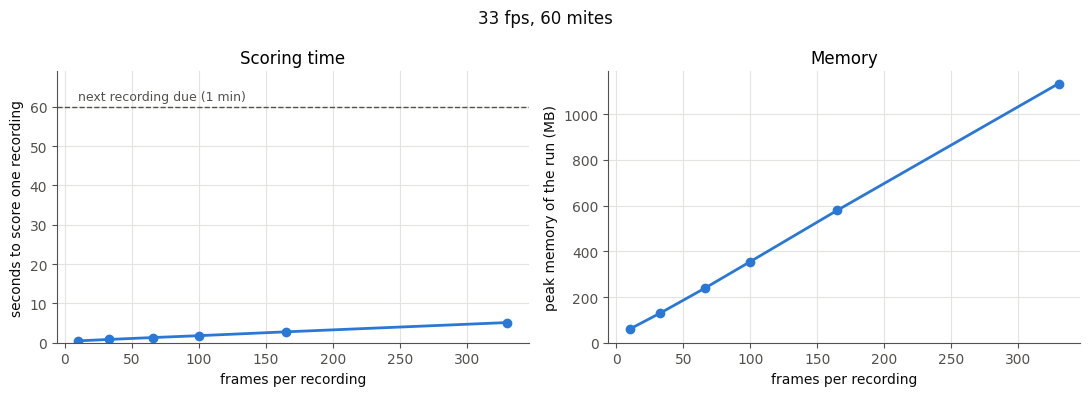

In [4]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
left.plot(by_frames.frame_count, by_frames.score_s, "o-", color=BLUE, markersize=6)
left.axhline(CYCLE_S, color=MUTED, linestyle="--", linewidth=1)
left.annotate("next recording due (1 min)", (by_frames.frame_count.min(), CYCLE_S), xytext=(0, 5),
              textcoords="offset points", color=MUTED, fontsize=9)
left.set(xlabel="frames per recording", ylabel="seconds to score one recording", title="Scoring time")
left.set_ylim(0, max(CYCLE_S * 1.15, by_frames.score_s.max() * 1.1))
right.plot(by_frames.frame_count, by_frames.peak_mb, "o-", color=BLUE, markersize=6)
right.set(xlabel="frames per recording", ylabel="peak memory of the run (MB)", title="Memory")
right.set_ylim(0, None)
fig.suptitle(f"33 fps, {int(by_frames.mites.iloc[0])} mites", color=INK)
fig.tight_layout()

## 3. Capture while the analysis is still busy

The worst case: each burst starts as soon as the one before is captured, while it is still being scored (what happens once scoring takes longer than the time between recordings). Are frames dropped then?

In [5]:
busy = sweep([(33, 100), (33, 330)], recordings=3, back_to_back=True)
busy[COLUMNS]

{'fps': 33, 'frame_count': 100, 'dropped': 0, 'capture_s': 3.04, 'score_s': 1.761, 'peak_mb': 513.7}


{'fps': 33, 'frame_count': 330, 'dropped': 0, 'capture_s': 10.0, 'score_s': 5.005, 'peak_mb': 1543.8}


,fps,frame_count,mites,dropped,late,expected_s,capture_s,score_s,analysed_s,peak_mb,cpu
0,33,100,60,0,1,3.03,3.04,1.761,1.682,513.7,1.58
1,33,330,60,0,0,10.00,10.00,5.005,5.233,1543.8,1.68


## 4. Beyond the camera

The camera cannot go past 33 fps; the stand-in can. Where would the capture path itself (frame handler copy, router, BMP writing) stop keeping up? 2 s bursts.

In [6]:
beyond = sweep([(fps, 2 * fps) for fps in (33, 60, 100, 150)])
beyond[COLUMNS]

{'fps': 33, 'frame_count': 66, 'dropped': 0, 'capture_s': 1.998, 'score_s': 1.254, 'peak_mb': 239.9}


{'fps': 60, 'frame_count': 120, 'dropped': 0, 'capture_s': 1.996, 'score_s': 2.088, 'peak_mb': 421.1}


{'fps': 100, 'frame_count': 200, 'dropped': 0, 'capture_s': 2.033, 'score_s': 3.071, 'peak_mb': 694.4}


{'fps': 150, 'frame_count': 300, 'dropped': 0, 'capture_s': 1.999, 'score_s': 4.767, 'peak_mb': 1039.8}


,fps,frame_count,mites,dropped,late,expected_s,capture_s,score_s,analysed_s,peak_mb,cpu
0,33,66,60,0,0,2.0,1.998,1.254,1.308,239.9,1.21
1,60,120,60,0,1,2.0,1.996,2.088,2.158,421.1,1.70
2,100,200,60,0,10,2.0,2.033,3.071,3.152,694.4,2.45
3,150,300,60,0,8,2.0,1.999,4.767,4.858,1039.8,2.86


## 5. Memory before and after holding frames grey

Up to commit 2fe59bd, each camera frame was held twice for the whole recording: the grey frame and a 3-channel copy made for the analysis (4 x the grey size), and folder mode decoded every frame in 3 channels. Now a frame is held once, grey, from the camera (or the file) to the score. Same runs, both versions of the code.

{'fps': 33, 'frame_count': 10, 'dropped': 0, 'capture_s': 0.295, 'score_s': 0.468, 'peak_mb': 58.5}


{'fps': 33, 'frame_count': 33, 'dropped': 0, 'capture_s': 1.015, 'score_s': 0.853, 'peak_mb': 131.1}


{'fps': 33, 'frame_count': 100, 'dropped': 0, 'capture_s': 3.012, 'score_s': 1.656, 'peak_mb': 356.6}


{'fps': 33, 'frame_count': 165, 'dropped': 0, 'capture_s': 4.98, 'score_s': 2.794, 'peak_mb': 576.1}


{'fps': 33, 'frame_count': 10, 'dropped': 0, 'capture_s': 0.304, 'score_s': 0.444, 'peak_mb': 232.6}


{'fps': 33, 'frame_count': 33, 'dropped': 0, 'capture_s': 1.016, 'score_s': 0.819, 'peak_mb': 818.9}


{'fps': 33, 'frame_count': 100, 'dropped': 0, 'capture_s': 3.023, 'score_s': 1.652, 'peak_mb': 2415.3}


{'fps': 33, 'frame_count': 165, 'dropped': 0, 'capture_s': 5.0, 'score_s': 2.802, 'peak_mb': 4009.3}


code,before (2fe59bd),grey (now)
frame_count,,
10,232.6,58.5
33,818.9,131.1
100,2415.3,356.6
165,4009.3,576.1


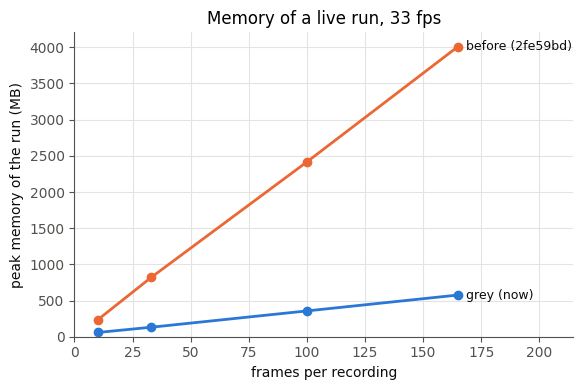

In [7]:
if OLD_CODE is None:
    print("No checkout of the old code: skipped.")
else:
    configs = [(33, frames) for frames in (10, 33, 100, 165)]
    new = sweep(configs).assign(code="grey (now)")
    old = sweep(configs, code=OLD_CODE).assign(code="before (2fe59bd)")
    compared = pd.concat([old, new])
    display(compared.pivot(index="frame_count", columns="code", values="peak_mb"))
    fig, ax = plt.subplots(figsize=(6, 4))
    for name, colour in (("before (2fe59bd)", ORANGE), ("grey (now)", BLUE)):
        part = compared[compared.code == name]
        ax.plot(part.frame_count, part.peak_mb, "o-", color=colour, markersize=6)
        ax.annotate(name, (part.frame_count.iloc[-1], part.peak_mb.iloc[-1]), xytext=(6, 0),
                    textcoords="offset points", color=INK, fontsize=9, va="center")
    ax.set(xlabel="frames per recording", ylabel="peak memory of the run (MB)", title="Memory of a live run, 33 fps")
    ax.set_ylim(0, None)
    ax.set_xlim(0, part.frame_count.max() * 1.3)
    fig.tight_layout()

## 6. The limits, from these measurements

In [8]:
import numpy as np

per_frame_s = np.polyfit(by_frames.frame_count, by_frames.score_s, 1)
per_frame_mb = np.polyfit(by_frames.frame_count, by_frames.peak_mb, 1)
most_frames = int((CYCLE_S - per_frame_s[1]) / per_frame_s[0])
print(f"scoring: {per_frame_s[0]:.3f} s per frame + {per_frame_s[1]:.2f} s per recording ({int(by_frames.mites.iloc[0])} mites)")
print(f"memory:  {per_frame_mb[0]:.1f} MB per frame of a recording + {per_frame_mb[1]:.0f} MB")
print(f"frames dropped at 5-33 fps: {int(by_fps.dropped.sum())}; while busy: {int(busy.dropped.sum())}")
print(f"=> at most ~{most_frames} frames per recording keep scoring under {CYCLE_S} s here "
      f"({most_frames / 33:.0f} s at 33 fps, {most_frames / 10:.0f} s at 10 fps)")

scoring: 0.015 s per frame + 0.35 s per recording (60 mites)
memory:  3.4 MB per frame of a recording + 20 MB
frames dropped at 5-33 fps: 0; while busy: 0
=> at most ~4110 frames per recording keep scoring under 60 s here (125 s at 33 fps, 411 s at 10 fps)


## What this means (Windows laptop, 2026-10-15, 60 mites)

- **The camera's full 33 fps can be used.** No frame was dropped at any rate, not at 60 to 150 fps (beyond what the camera can do) and not while the recording before was still being scored. The frames the stand-in camera itself delivered late at 100 and 150 fps are the stand-in falling behind its own clock, not frames lost by the app.
- **Scoring is not the limit.** About 0.015 s per frame plus 0.35 s per recording: a 1 s burst at 33 fps is scored in under 1 s, and the next recording is due a minute later at the soonest. It would take some 4000 frames per recording to use up that minute.
- **Memory grows with the frames per recording**, about 3.4 MB per frame (the frame is 3 MB), whatever the frame rate. The app refuses a recording of more than 2 GB of frames (`MAX_BURST_BYTES`): 670 frames, 20 s at 33 fps.
- **Disk space grows the same way**: every frame is a 3 MB BMP. A run like the long one (295 recordings) takes 8.8 GB at 10 frames per recording, 29 GB at 33 and 89 GB at 100. During a burst at 33 fps the frames are written at 100 MB/s.
- **Before the frames were held grey** a run took 6 to 7 times the memory: each frame was held twice (grey and a 3-channel copy, 4 x the grey size), and the recording before was kept until the next one was complete.

Run this notebook on the Discobox laptop for its own numbers: it is likely slower than this one, and its disk decides how fast frames can be written.